# 3. Follow a population through time

As stars evolve, the overall properties of the population to which they belong change. Individual stars become brighter or fainter and their effective temperatures change as they pass through different evolutionary stages. This affects both the total radiation emitted by the population and the relative contributions of hotter and cooler stars.

In this tutorial, we will explore how two population-level properties evolve over time: the **total bolometric luminosity** and the **luminosity-weighted mean effective temperature**. This tutorial is a direct continuation of the previous one; if you haven't checked it yet, I recommend you to do so!

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import arsenal_gear as ag

We recreate the SSP from the previous tutorials, with the same parameters and random seed.

In [2]:
ssp_parameters = {
    "type": "single",
    "Mtot": 1e5 * u.Msun,
    "tform": 0 * u.Myr,
    "metallicity": 0.0,
    "rotation": 0.0,
    "imf": "kroupa2001",
    "mmin": 0.1 * u.Msun,
    "mmax": 100 * u.Msun,
    "discrete": True,
    "seed": 42,
}

sp = ag.SynthPop(pop1=ssp_parameters, interp_op="iso", vvcrit="0.0")
pop = sp.form.subpops[0] # The initial stellar population information
se = sp.evol.ses[0] # The evolution interface for the first subpopulation

As in the previous tutorial, we distinguish the population's age, $\tau$, from the time passed to the population methods, the absolute time, $t$:

$$
\tau = t - t_{\mathrm{form}}, \qquad t = t_{\mathrm{form}} + \tau.
$$

Here, $t_{\mathrm{form}}=0$, so time and age have the same numerical value. We still include the formation time explicitly when constructing the array of evaluation times.

At young ages, the population’s light is dominated by massive stars that evolve rapidly. We therefore choose 100 logarithmically spaced ages from $1\,\mathrm{Myr}$ to $1\,\mathrm{Gyr}$ in order to have more closely spaced evaluation times during these early stages.

In [3]:
ages = np.geomspace(1, 1000, 100) * u.Myr
t = pop.tform + ages

We can pass this array directly to `sp.bol(t)` and `sp.teff`. These methods query the evolutionary models at the corresponding stellar ages and return one value per evaluation time, retaining the physical units.

We can then plot the luminosity and luminosity-weighted temperature histories.

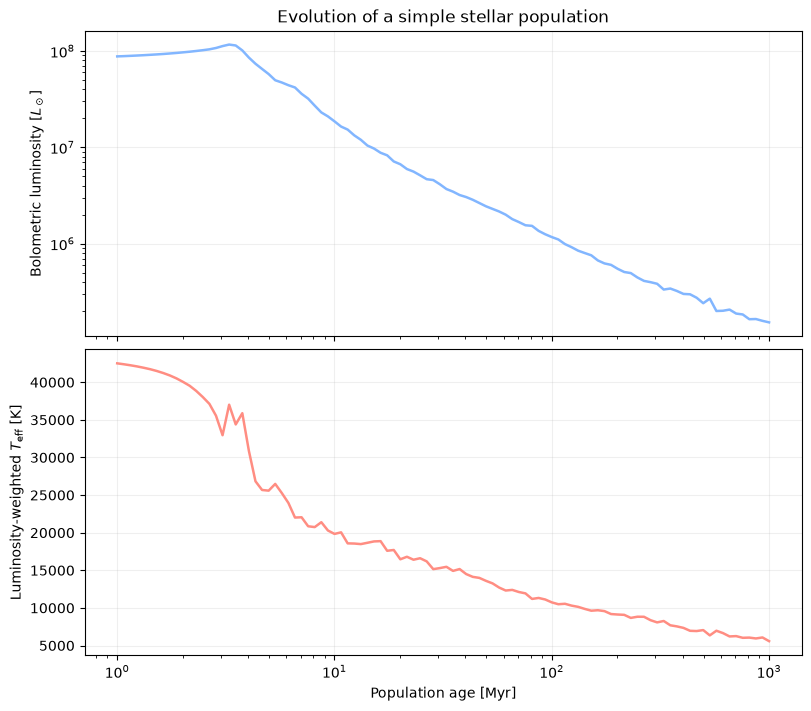

In [4]:
lbol = sp.lbol(t)
teff = sp.teff(t)

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True, layout="constrained")

axes[0].plot(ages.to_value(u.Myr), lbol.to_value(u.Lsun), color="#82B6FF", linewidth=1.8)
axes[0].set_yscale("log")
axes[0].set_ylabel(r"Bolometric luminosity [$L_\odot$]")
axes[0].set_title("Evolution of a simple stellar population")

axes[1].plot(ages.to_value(u.Myr), teff.to_value(u.K), color="#FF8D82", linewidth=1.8)
axes[1].set_ylabel(r"Luminosity-weighted $T_{\mathrm{eff}}$ [K]")
axes[1].set_xlabel("Population age [Myr]")
axes[1].set_xscale("log")

for ax in axes:
    ax.grid(alpha=0.2)

plt.show()

The **bolometric luminosity** initially rises, before declining over most of the interval. 
This happens because much of the light from young populations comes from massive stars that become brighter as they pass through different evolutionary stages. But these stars evolve rapidly and, as they approach the end of their lives, their contributions disappear from the sum and less massive stars increasingly supply the remaining light. 

The **luminosity-weighted effective temperature** generally decreases. Hot, massive stars dominate the light at young ages. As these stars evolve, many expand and their surfaces cool, lowering the luminosity-weighted mean effective temperature. Their eventual disappearance further shifts the light towards longer-lived, generally cooler stars.

